In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
sys.path.append('..')
from src.schema import DATE_COL, STORE_COL, ITEM_COL, SALES_COL

print("All imports OK")

All imports OK


In [8]:
df_raw = pd.read_csv('../data/raw/train.csv')
print(df_raw.shape)
print(df_raw.head())

(913000, 4)
         date  store  item  sales
0  2013-01-01      1     1     13
1  2013-01-02      1     1     11
2  2013-01-03      1     1     14
3  2013-01-04      1     1     13
4  2013-01-05      1     1     10


In [9]:
# --- Cell: Load & Clean ---
df_raw[DATE_COL] = pd.to_datetime(df_raw[DATE_COL])

# Basic cleaning: ensure types are correct, sort
df = df_raw.copy()
df[STORE_COL] = df[STORE_COL].astype(int)
df[ITEM_COL] = df[ITEM_COL].astype(int)
df = df.sort_values([STORE_COL, ITEM_COL, DATE_COL]).reset_index(drop=True)

print("Shape:", df.shape)
print("Date range:", df[DATE_COL].min(), "→", df[DATE_COL].max())
print("Stores:", df[STORE_COL].nunique())
print("Items:", df[ITEM_COL].nunique())
print("Missing values:\n", df.isnull().sum())

Shape: (913000, 4)
Date range: 2013-01-01 00:00:00 → 2017-12-31 00:00:00
Stores: 10
Items: 50
Missing values:
 date     0
store    0
item     0
sales    0
dtype: int64


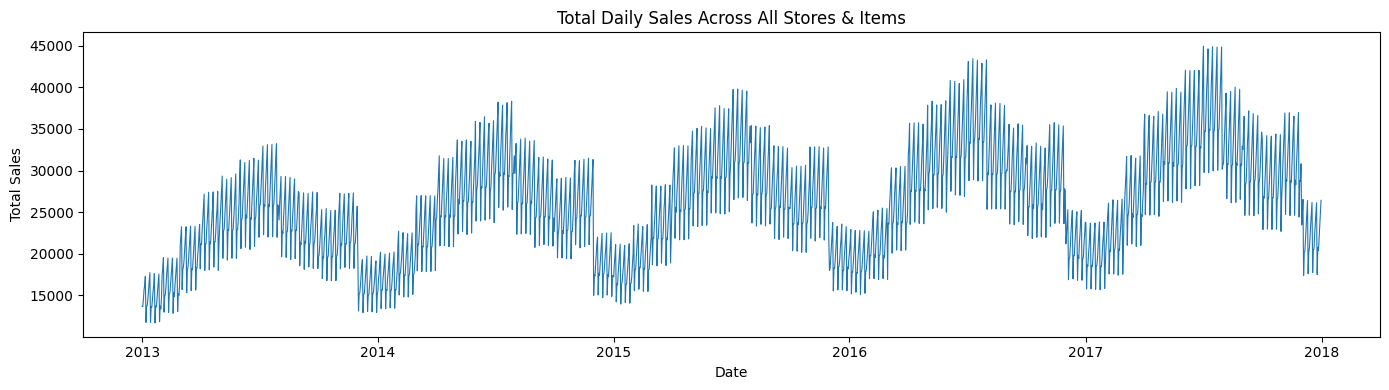

In [10]:
daily_sales = df.groupby(DATE_COL)[SALES_COL].sum().reset_index()

plt.figure(figsize=(14, 4))
plt.plot(daily_sales[DATE_COL], daily_sales[SALES_COL], linewidth=0.8)
plt.title("Total Daily Sales Across All Stores & Items")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

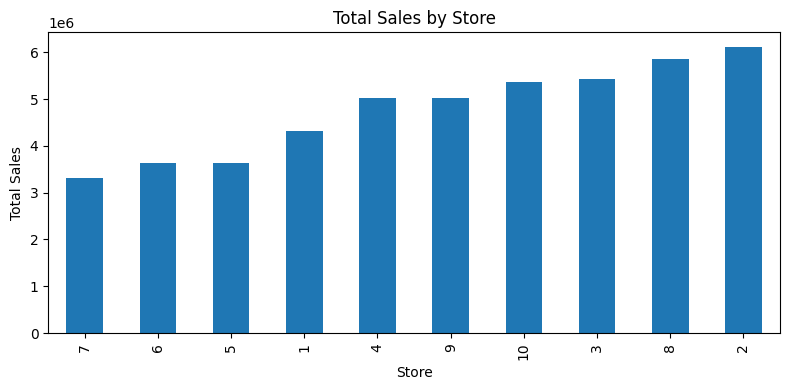

In [11]:
store_sales = df.groupby(STORE_COL)[SALES_COL].sum().sort_values()

plt.figure(figsize=(8, 4))
store_sales.plot(kind='bar')
plt.title("Total Sales by Store")
plt.xlabel("Store")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

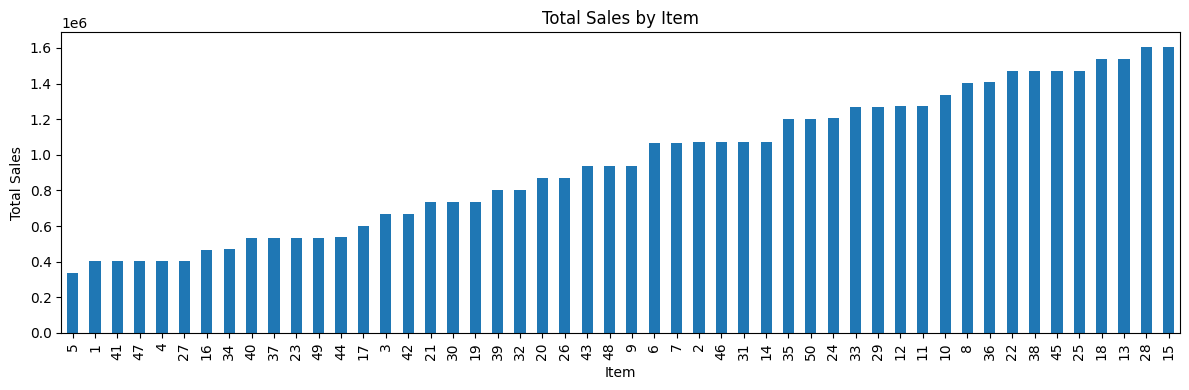

In [12]:
item_sales = df.groupby(ITEM_COL)[SALES_COL].sum().sort_values()

plt.figure(figsize=(12, 4))
item_sales.plot(kind='bar')
plt.title("Total Sales by Item")
plt.xlabel("Item")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

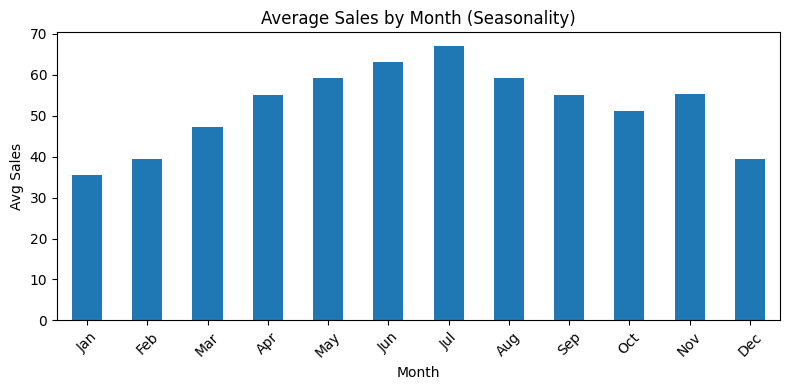

In [13]:
df['month'] = df[DATE_COL].dt.month
monthly = df.groupby('month')[SALES_COL].mean()

plt.figure(figsize=(8, 4))
monthly.plot(kind='bar')
plt.title("Average Sales by Month (Seasonality)")
plt.xlabel("Month")
plt.ylabel("Avg Sales")
plt.xticks(ticks=range(12), labels=['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'], rotation=45)
plt.tight_layout()
plt.show()

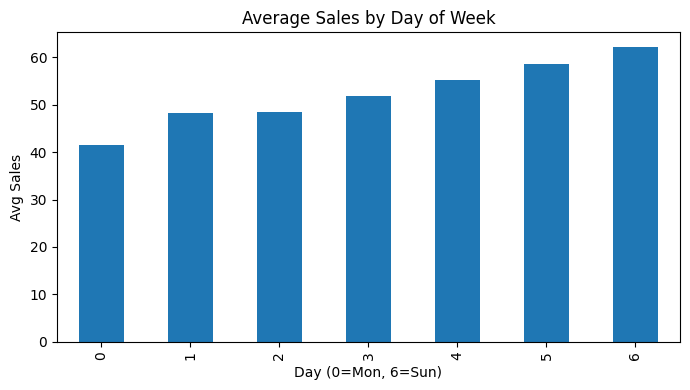

In [14]:
df['dayofweek'] = df[DATE_COL].dt.dayofweek
dow = df.groupby('dayofweek')[SALES_COL].mean()

plt.figure(figsize=(7, 4))
dow.plot(kind='bar')
plt.title("Average Sales by Day of Week")
plt.xlabel("Day (0=Mon, 6=Sun)")
plt.ylabel("Avg Sales")
plt.tight_layout()
plt.show()

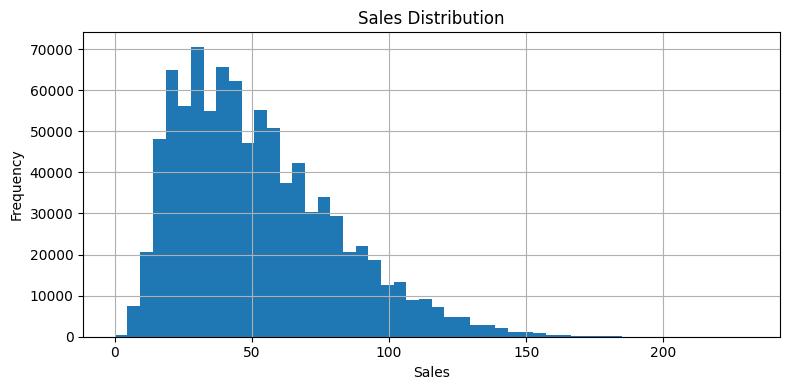

Stats:
count    913000.000000
mean         52.250287
std          28.801144
min           0.000000
25%          30.000000
50%          47.000000
75%          70.000000
max         231.000000
Name: sales, dtype: float64


In [15]:
plt.figure(figsize=(8, 4))
df[SALES_COL].hist(bins=50)
plt.title("Sales Distribution")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

print("Stats:")
print(df[SALES_COL].describe())

In [ ]:
// Feature engineering cells >>>>

In [16]:
# Work on a copy, sorted per SKU-store series
df_feat = df.copy()
df_feat = df_feat.sort_values([STORE_COL, ITEM_COL, DATE_COL]).reset_index(drop=True)

In [17]:
# Lags must be >= 28 days (our forecast horizon)
# We create lag-28, lag-35, lag-42, lag-56, lag-91, lag-364 (same day last year)
lag_days = [28, 35, 42, 56, 91, 364]

for lag in lag_days:
    df_feat[f'lag_{lag}'] = (
        df_feat.groupby([STORE_COL, ITEM_COL])[SALES_COL]
        .shift(lag)
    )

print("Lag columns added:", [f'lag_{l}' for l in lag_days])
print(df_feat[[SALES_COL, 'lag_28', 'lag_364']].head(10))

Lag columns added: ['lag_28', 'lag_35', 'lag_42', 'lag_56', 'lag_91', 'lag_364']
   sales  lag_28  lag_364
0     13     NaN      NaN
1     11     NaN      NaN
2     14     NaN      NaN
3     13     NaN      NaN
4     10     NaN      NaN
5     12     NaN      NaN
6     10     NaN      NaN
7      9     NaN      NaN
8     12     NaN      NaN
9      9     NaN      NaN


In [18]:
# Rolling mean and std MUST be shifted by 28 before the window
# e.g. rolling_mean_7 = mean of days [t-35 .. t-28], not [t-7 .. t-1]
windows = [7, 14, 28]

for w in windows:
    shifted = df_feat.groupby([STORE_COL, ITEM_COL])[SALES_COL].shift(28)
    df_feat[f'rolling_mean_{w}'] = (
        shifted.groupby([df_feat[STORE_COL], df_feat[ITEM_COL]])
        .transform(lambda x: x.rolling(w, min_periods=1).mean())
    )
    df_feat[f'rolling_std_{w}'] = (
        shifted.groupby([df_feat[STORE_COL], df_feat[ITEM_COL]])
        .transform(lambda x: x.rolling(w, min_periods=1).std())
    )

print("Rolling columns added:", [f'rolling_mean_{w}' for w in windows] + [f'rolling_std_{w}' for w in windows])

Rolling columns added: ['rolling_mean_7', 'rolling_mean_14', 'rolling_mean_28', 'rolling_std_7', 'rolling_std_14', 'rolling_std_28']


In [19]:
# These are safe — they come from the date itself, not from sales
df_feat['year']        = df_feat[DATE_COL].dt.year
df_feat['month']       = df_feat[DATE_COL].dt.month
df_feat['day']         = df_feat[DATE_COL].dt.day
df_feat['dayofweek']   = df_feat[DATE_COL].dt.dayofweek      # 0=Mon
df_feat['dayofyear']   = df_feat[DATE_COL].dt.dayofyear
df_feat['weekofyear']  = df_feat[DATE_COL].dt.isocalendar().week.astype(int)
df_feat['quarter']     = df_feat[DATE_COL].dt.quarter
df_feat['is_weekend']  = (df_feat['dayofweek'] >= 5).astype(int)
df_feat['is_month_start'] = df_feat[DATE_COL].dt.is_month_start.astype(int)
df_feat['is_month_end']   = df_feat[DATE_COL].dt.is_month_end.astype(int)

print("Calendar features added.")
print(df_feat.columns.tolist())

Calendar features added.
['date', 'store', 'item', 'sales', 'month', 'dayofweek', 'lag_28', 'lag_35', 'lag_42', 'lag_56', 'lag_91', 'lag_364', 'rolling_mean_7', 'rolling_std_7', 'rolling_mean_14', 'rolling_std_14', 'rolling_mean_28', 'rolling_std_28', 'year', 'day', 'dayofyear', 'weekofyear', 'quarter', 'is_weekend', 'is_month_start', 'is_month_end']


In [20]:
print("Null counts per feature column:")
feat_cols = [c for c in df_feat.columns if c not in [DATE_COL, STORE_COL, ITEM_COL, SALES_COL]]
print(df_feat[feat_cols].isnull().sum())
print("\nTotal rows:", len(df_feat))
print("Rows with no nulls:", df_feat.dropna().shape[0])

Null counts per feature column:
month                   0
dayofweek               0
lag_28              14000
lag_35              17500
lag_42              21000
lag_56              28000
lag_91              45500
lag_364            182000
rolling_mean_7      14000
rolling_std_7       14500
rolling_mean_14     14000
rolling_std_14      14500
rolling_mean_28     14000
rolling_std_28      14500
year                    0
day                     0
dayofyear               0
weekofyear              0
quarter                 0
is_weekend              0
is_month_start          0
is_month_end            0
dtype: int64

Total rows: 913000
Rows with no nulls: 731000


In [ ]:
//Save the feature tale 